Challenge: Detecting Regime Change of UNG (US Natural Gas Front Month Data)

In [ ]:
!pip install ruptures

In [ ]:
!pip install hmmlearn

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import ruptures as rpt
from hmmlearn.hmm import GaussianHMM
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [ ]:
ung = yf.download("UNG", start="2015-01-01", auto_adjust=True)
ung = ung['Close'].dropna()
ung_values = ung.values
ung_dates = ung.index
ung_values_log = np.log(ung_series.values)
n = len(ung_values)

[*********************100%***********************]  1 of 1 completed


In [ ]:
ung.head()

Ticker,UNG
Date,
2015-01-02,239.360001
2015-01-05,237.919998
2015-01-06,238.880005
2015-01-07,233.279999
2015-01-08,239.039993


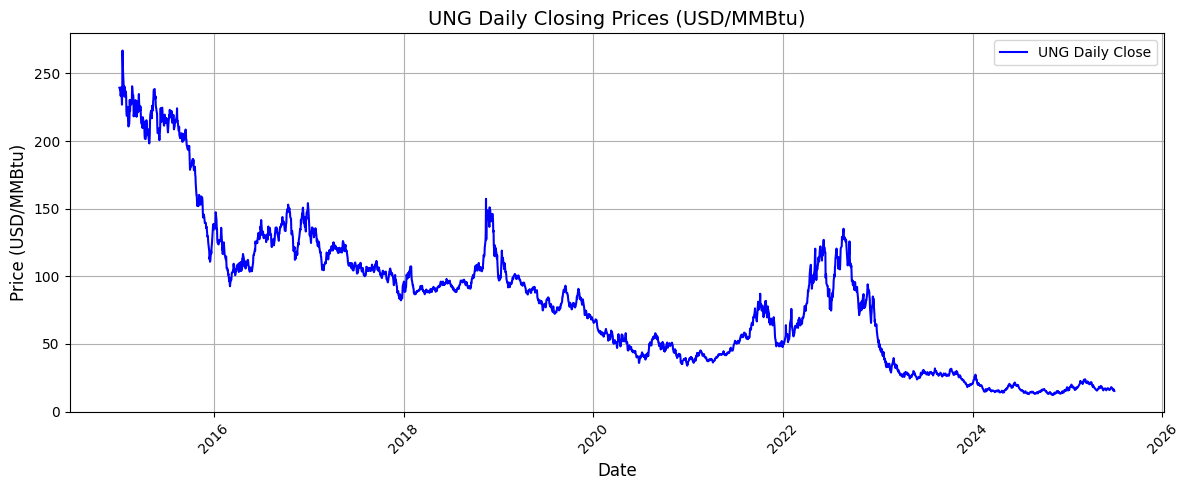

In [ ]:
import matplotlib.pyplot as plt

# Plot UNG closing prices over time
plt.figure(figsize=(12, 5))
plt.plot(ung_dates, ung_values, label="UNG Daily Close", color='blue')
plt.title("UNG Daily Closing Prices (USD/MMBtu)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Price (USD/MMBtu)", fontsize=12)
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


--- Penalty: 10 ---


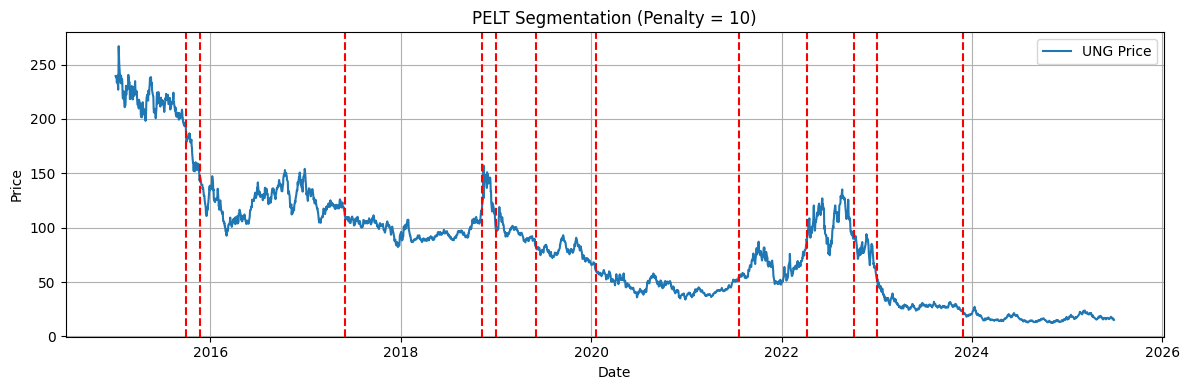

Segment Means and Variances:
  Segment 1: Mean = 217.71, Variance = 155.84
  Segment 2: Mean = 168.51, Variance = 204.17
  Segment 3: Mean = 123.84, Variance = 166.14
  Segment 4: Mean = 97.85, Variance = 53.63
  Segment 5: Mean = 132.89, Variance = 180.33
  Segment 6: Mean = 96.06, Variance = 43.69
  Segment 7: Mean = 78.09, Variance = 41.12
  Segment 8: Mean = 46.17, Variance = 43.40
  Segment 9: Mean = 64.27, Variance = 99.47
  Segment 10: Mean = 106.91, Variance = 191.73
  Segment 11: Mean = 78.03, Variance = 90.76
  Segment 12: Mean = 29.87, Variance = 26.71
  Segment 13: Mean = 17.03, Variance = 8.12

--- Penalty: 30 ---


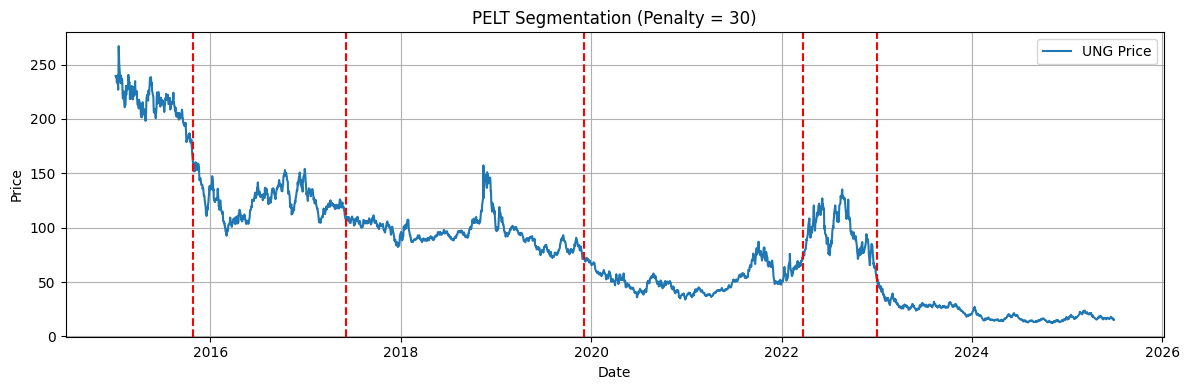

Segment Means and Variances:
  Segment 1: Mean = 214.22, Variance = 256.81
  Segment 2: Mean = 125.21, Variance = 205.49
  Segment 3: Mean = 95.78, Variance = 179.92
  Segment 4: Mean = 52.35, Variance = 128.35
  Segment 5: Mean = 96.67, Variance = 339.37
  Segment 6: Mean = 21.67, Variance = 52.92

--- Penalty: 50 ---


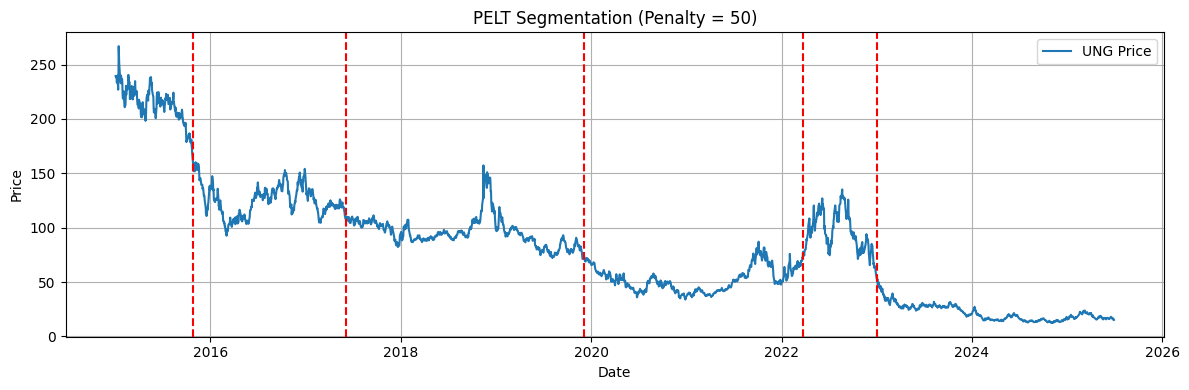

Segment Means and Variances:
  Segment 1: Mean = 214.22, Variance = 256.81
  Segment 2: Mean = 125.21, Variance = 205.49
  Segment 3: Mean = 95.78, Variance = 179.92
  Segment 4: Mean = 52.35, Variance = 128.35
  Segment 5: Mean = 96.67, Variance = 339.37
  Segment 6: Mean = 21.67, Variance = 52.92

--- Penalty: 100 ---


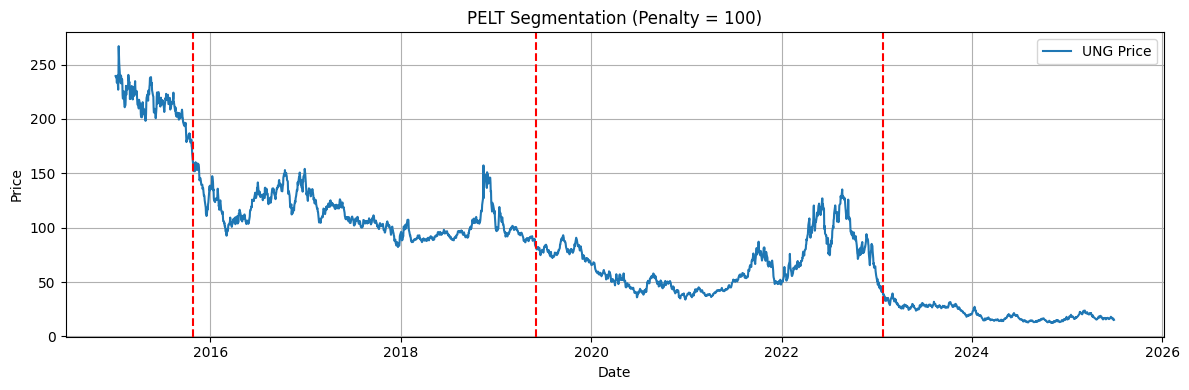

Segment Means and Variances:
  Segment 1: Mean = 214.22, Variance = 256.81
  Segment 2: Mean = 111.17, Variance = 330.20
  Segment 3: Mean = 65.58, Variance = 508.80
  Segment 4: Mean = 21.08, Variance = 39.86

Summary of AIC and BIC by Penalty:


,Penalty,AIC,BIC
0,10,350366.94,1314149.57
1,30,481199.25,882775.35
2,50,481199.25,882775.35
3,100,878845.83,1119791.49


In [ ]:
def cost_l2(x, start, end):
    segment = x[start:end]
    mu = np.mean(segment)
    return np.sum((segment - mu) ** 2)

def compute_bic(loss, k, n, sigma2):
    return loss + 4 * sigma2 * np.log(n) * k

def compute_aic(loss, k, sigma2):
    return loss + 4 * sigma2 * k

ung_series = ung["UNG"]
ung_values = ung_series.values
dates = ung_series.index
n = len(ung_values)
sigma2 = np.var(ung_values)

penalties = [10, 30, 50, 100]
results = []

for pen in penalties:
    print(f"\n--- Penalty: {pen} ---")

    model = rpt.Pelt(model="rbf").fit(ung_values)
    bkps = model.predict(pen=pen)
    bkps = [0] + bkps

    plt.figure(figsize=(12, 4))
    plt.plot(dates, ung_values, label="UNG Price")
    for bkp in bkps[1:]:
        if bkp < len(dates):
            plt.axvline(dates[bkp], color='red', linestyle='--')
    plt.title(f"PELT Segmentation (Penalty = {pen})")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    loss = 0
    seg_means_vars = []

    for i in range(len(bkps) - 1):
        start, end = bkps[i], bkps[i + 1]
        segment = ung_values[start:end]
        mu = np.mean(segment)
        var = np.var(segment)
        seg_means_vars.append((mu, var))
        loss += cost_l2(ung_values, start, end)

    k = len(bkps) - 2
    aic = compute_aic(loss, k, sigma2)
    bic = compute_bic(loss, k, n, sigma2)
    results.append({"Penalty": pen, "AIC": round(aic, 2), "BIC": round(bic, 2)})

    print("Segment Means and Variances:")
    for i, (mu, var) in enumerate(seg_means_vars):
        print(f"  Segment {i+1}: Mean = {mu:.2f}, Variance = {var:.2f}")

results_df = pd.DataFrame(results)
print("\nSummary of AIC and BIC by Penalty:")
display(results_df)


--- Penalty: 2e-11 ---


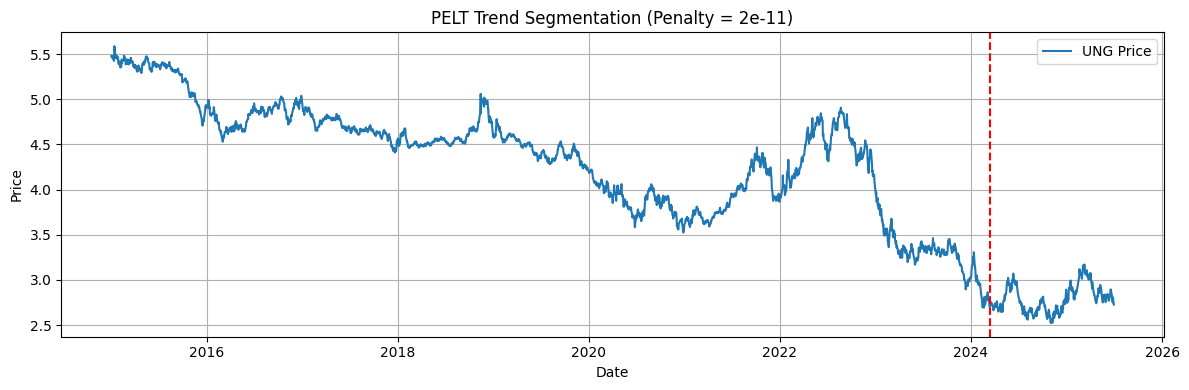

Segment Mean, Variance, and Trend (Slope):
  Segment 1:
    Mean      = 4.3518
    Variance  = 0.3671
    Slope     = -0.000761
  Segment 2:
    Mean      = 2.7917
    Variance  = 0.0226
    Slope     = 0.000546

--- Penalty: 1e-11 ---


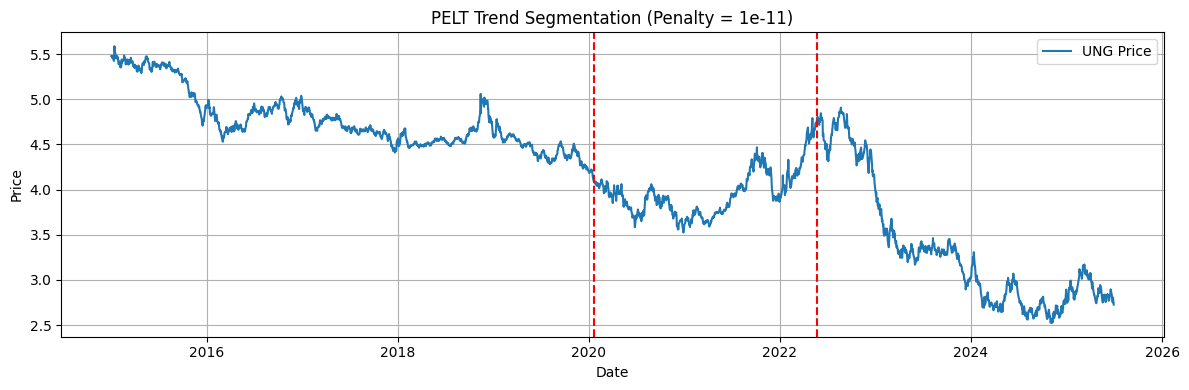

Segment Mean, Variance, and Trend (Slope):
  Segment 1:
    Mean      = 4.7625
    Variance  = 0.1020
    Slope     = -0.000748
  Segment 2:
    Mean      = 3.9637
    Variance  = 0.0667
    Slope     = 0.000825
  Segment 3:
    Mean      = 3.3281
    Variance  = 0.4577
    Slope     = -0.002591

Summary of AIC and BIC by Penalty (Trend Model):


,Penalty,AIC,BIC
0,2.000000e-11,58894.29,139209.51
1,1.000000e-11,70571.79,231202.23


In [ ]:
signal_2d = ung_values_log.reshape(-1, 1)

penalties = [0.00000000002,0.00000000001]
results = []

for pen in penalties:
    print(f"\n--- Penalty: {pen} ---")

    model = rpt.Pelt(model="linear").fit(signal_2d)
    bkps = model.predict(pen=pen)
    bkps = [0] + bkps

    plt.figure(figsize=(12, 4))
    plt.plot(dates, ung_values_log, label="UNG Price")
    for bkp in bkps[1:]:
        if bkp < len(dates):
            plt.axvline(dates[bkp], color='red', linestyle='--')
    plt.title(f"PELT Trend Segmentation (Penalty = {pen})")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    cost_model = rpt.costs.CostLinear().fit(signal_2d)
    loss = 0
    seg_stats = []

    for i in range(len(bkps) - 1):
        start, end = bkps[i], bkps[i + 1]
        segment = ung_values_log[start:end]
        mu = np.mean(segment)
        var = np.var(segment)
        seg_stats.append((mu, var))
        loss += cost_model.error(start, end)

    k = len(bkps) - 2
    aic = compute_aic(loss, k, sigma2)
    bic = compute_bic(loss, k, n, sigma2)
    results.append({"Penalty": pen, "AIC": round(aic, 2), "BIC": round(bic, 2)})

    print("Segment Mean, Variance, and Trend (Slope):")
    for i in range(len(bkps) - 1):
        start, end = bkps[i], bkps[i + 1]
        segment = ung_values_log[start:end]

        mu = np.mean(segment)
        var = np.var(segment)

        x = np.arange(start, end)
        y = segment
        slope, intercept = np.polyfit(x, y, deg=1)

        print(f"  Segment {i+1}:")
        print(f"    Mean      = {mu:.4f}")
        print(f"    Variance  = {var:.4f}")
        print(f"    Slope     = {slope:.6f}")

results_df = pd.DataFrame(results)
print("\nSummary of AIC and BIC by Penalty (Trend Model):")
display(results_df)

In [ ]:
X = ung_values.reshape(-1, 1)
signal_2d = X
for n_regimes in range(1, 10):
    model = GaussianHMM(n_components=n_regimes, covariance_type="full", n_iter=1000).fit(signal_2d)
    log_likelihood = model.score(signal_2d)
    n_params = n_regimes * 3  # mean, variance, transition for each
    bic = -2 * log_likelihood + n_params * np.log(len(signal_2d))
    print(f"{n_regimes} regimes: BIC = {bic:.2f}")

1 regimes: BIC = 28558.88
2 regimes: BIC = 25132.91
3 regimes: BIC = 22898.20
4 regimes: BIC = 23472.49
5 regimes: BIC = 22945.12
6 regimes: BIC = 21177.40
7 regimes: BIC = 19077.59
8 regimes: BIC = 19026.15
9 regimes: BIC = 18910.48


In [ ]:
X = ung_values.reshape(-1, 1)
model = GaussianHMM(n_components=5, covariance_type="full", n_iter=1000, random_state=42)
model.fit(X)

GaussianHMM(covariance_type='full', n_components=5, n_iter=1000,
            random_state=42)

In [ ]:
hidden_states = model.predict(X)
posteriors = model.predict_proba(ung_values.reshape(-1, 1))
entropy = -np.sum(posteriors * np.log(posteriors + 1e-12), axis=1)

In [ ]:
for i in range(model.n_components):
    print(f"Regime {i}:")
    print(f"  Mean     = {model.means_[i][0]:.4f}")
    print(f"  Std Dev  = {np.sqrt(model.covars_[i][0][0]):.4f}")

Regime 0:
  Mean     = 102.8223
  Std Dev  = 21.4245
Regime 1:
  Mean     = 103.0603
  Std Dev  = 21.4251
Regime 2:
  Mean     = 214.2573
  Std Dev  = 15.9823
Regime 3:
  Mean     = 33.1304
  Std Dev  = 15.0777
Regime 4:
  Mean     = 102.7296
  Std Dev  = 21.4871


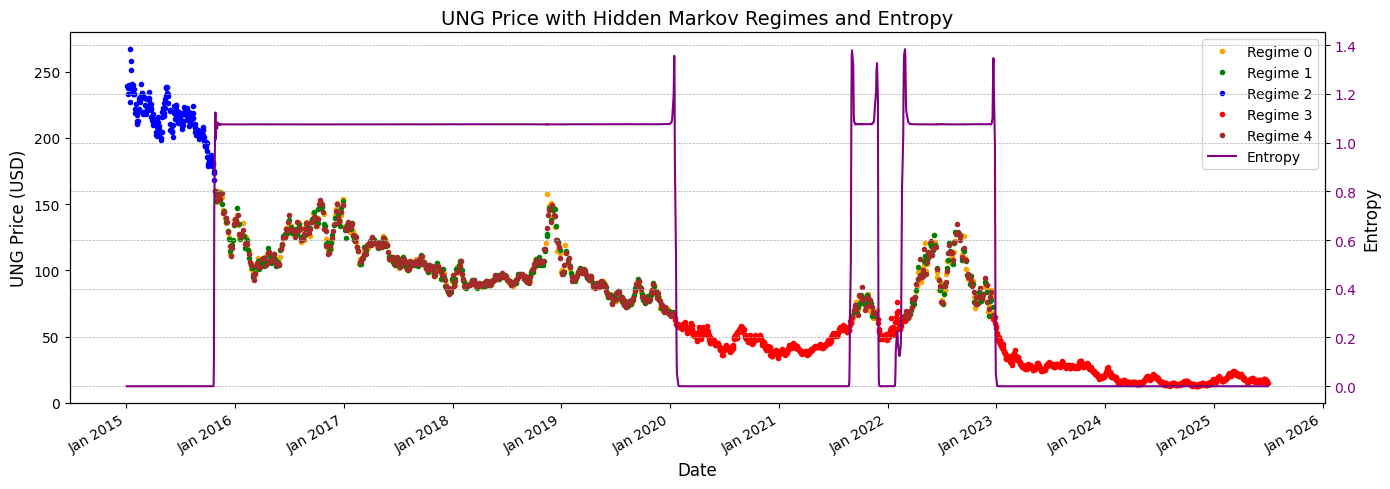

In [ ]:
colors = ['orange', 'green', 'blue', 'red', 'brown']  # For 5 regimes

fig, ax1 = plt.subplots(figsize=(14, 5))

for regime in np.unique(hidden_states):
    mask = hidden_states == regime
    ax1.plot(dates[mask], ung_values[mask], '.', label=f'Regime {regime}', color=colors[regime])

ax1.set_xlabel("Date", fontsize=12)
ax1.set_ylabel("UNG Price (USD)", fontsize=12)
ax1.set_title("UNG Price with Hidden Markov Regimes and Entropy", fontsize=14)
ax1.tick_params(axis='y')

ax1.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()

ax2 = ax1.twinx()
ax2.plot(dates, entropy, color='purple', label='Entropy', linewidth=1.5)
ax2.set_ylabel("Entropy", fontsize=12)
ax2.tick_params(axis='y', labelcolor='purple')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=10)

plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

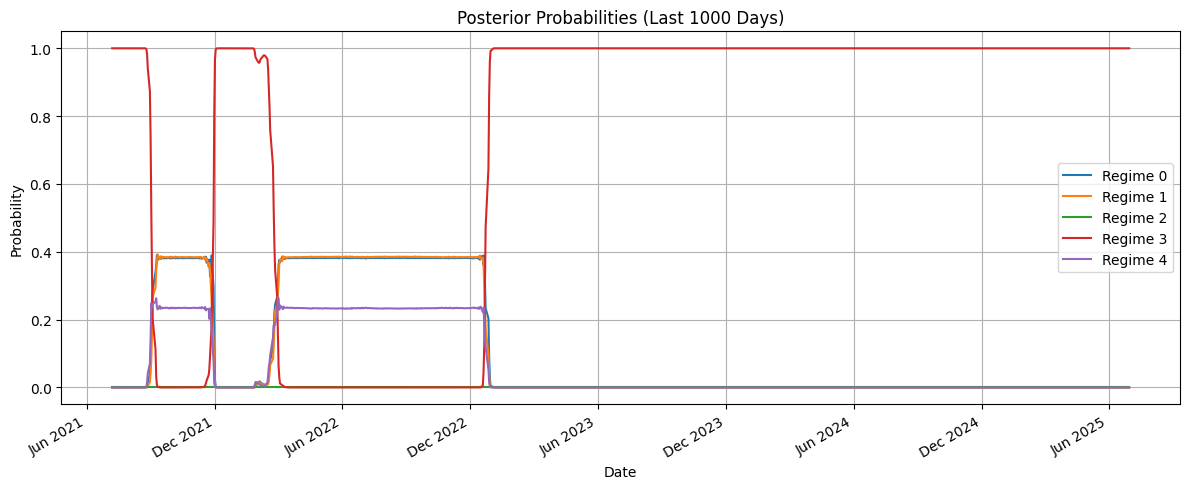

In [ ]:
window = 1000
plt.figure(figsize=(12, 5))

# Use only the last 'window' dates
date_window = dates[-window:]

for i in range(model.n_components):
    plt.plot(date_window, posteriors[-window:, i], label=f"Regime {i}")

plt.title("Posterior Probabilities (Last 1000 Days)")
plt.xlabel("Date")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)

# Set x-axis ticks every 6 months
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gcf().autofmt_xdate()  # Auto-format for readability

plt.tight_layout()
plt.show()

In [ ]:
X = ung_values_log.reshape(-1, 1)
signal_2d = X
for n_regimes in range(1, 9):
    model = GaussianHMM(n_components=n_regimes, covariance_type="full", n_iter=1000).fit(signal_2d)
    log_likelihood = model.score(signal_2d)
    n_params = n_regimes * 3  # mean, variance, transition for each
    bic = -2 * log_likelihood + n_params * np.log(len(signal_2d))
    print(f"{n_regimes} regimes: BIC = {bic:.2f}")

1 regimes: BIC = 6102.27
2 regimes: BIC = 2522.92
3 regimes: BIC = 2969.93
4 regimes: BIC = 2078.62
5 regimes: BIC = -1804.11
6 regimes: BIC = -478.22
7 regimes: BIC = -950.31
8 regimes: BIC = -2936.32


In [ ]:
model = GaussianHMM(n_components=2, covariance_type="full", n_iter=1000, random_state=42)
model.fit(X)

GaussianHMM(covariance_type='full', n_components=2, n_iter=1000,
            random_state=42)

In [ ]:
hidden_states = model.predict(X)
posteriors = model.predict_proba(ung_values_log.reshape(-1, 1))
entropy = -np.sum(posteriors * np.log(posteriors + 1e-12), axis=1)

In [ ]:
for i in range(model.n_components):
    print(f"Regime {i}:")
    print(f"  Mean     = {model.means_[i][0]:.4f}")
    print(f"  Std Dev  = {np.sqrt(model.covars_[i][0][0]):.4f}")

Regime 0:
  Mean     = 4.7075
  Std Dev  = 0.3251
Regime 1:
  Mean     = 3.3788
  Std Dev  = 0.4850


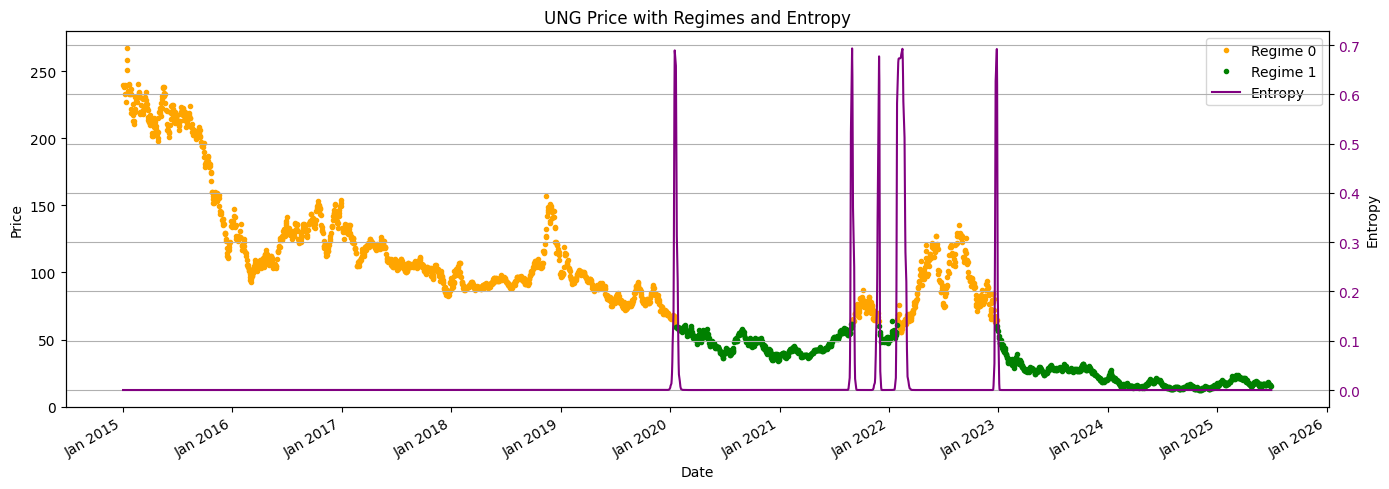

In [ ]:
colors = ['orange', 'green']

fig, ax1 = plt.subplots(figsize=(14, 5))

for regime in np.unique(hidden_states):
    mask = hidden_states == regime
    ax1.plot(dates[mask], ung_values[mask], '.', label=f'Regime {regime}', color=colors[regime])

ax1.set_xlabel("Date")
ax1.set_ylabel("Price")
ax1.set_title("UNG Price with Regimes and Entropy")
ax1.tick_params(axis='y')

ax1.xaxis.set_major_locator(mdates.MonthLocator(bymonth=1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()

ax2 = ax1.twinx()
ax2.plot(dates, entropy, color='purple', label='Entropy', linewidth=1.5)
ax2.set_ylabel("Entropy")
ax2.tick_params(axis='y', labelcolor='purple')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.grid(True)
plt.tight_layout()
plt.show()

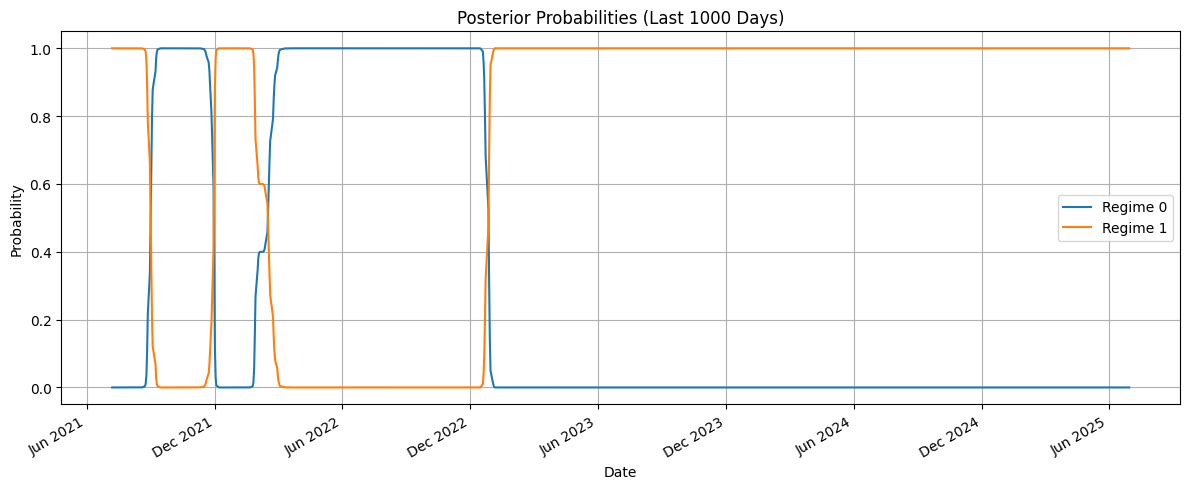

In [ ]:
window = 1000
plt.figure(figsize=(12, 5))

# Use only the last 'window' dates
date_window = dates[-window:]

for i in range(model.n_components):
    plt.plot(date_window, posteriors[-window:, i], label=f"Regime {i}")

plt.title("Posterior Probabilities (Last 1000 Days)")
plt.xlabel("Date")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)

# Set x-axis ticks every 6 months
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gcf().autofmt_xdate()  # Auto-format for readability

plt.tight_layout()
plt.show()

Challenge: Modeling Non-Stationarity and Finding an Equilibrium with SPY and QQQ Data

WQU QUANTITATIVE FINANCE: Non-Stationarity and Equilibrium Model
This demonstrates key concepts in pairs trading and statistical arbitrage
PART 1: SYNTHETIC DATA EXAMPLE (Perfect Cointegration)
--- Stationarity Check for Asset_X ---
ADF Statistic: -1.4986
p-value: 0.5342
Critical Values:
	1%: -3.4435
	5%: -2.8673
	10%: -2.5699
Conclusion: The series 'Asset_X' is likely NON-STATIONARY (p-value >= 0.05).
----------------------------------------
--- Stationarity Check for Asset_Y ---
ADF Statistic: -1.6714
p-value: 0.4459
Critical Values:
	1%: -3.4436
	5%: -2.8674
	10%: -2.5699
Conclusion: The series 'Asset_Y' is likely NON-STATIONARY (p-value >= 0.05).
----------------------------------------

--- Cointegration Check ---
Cointegration test p-value: 0.0000
Conclusion: The series are likely COINTEGRATED (p-value < 0.05).
Equilibrium relationship: Asset_Y = 1.5130 * Asset_X + 3.7861

--- Stationarity Check for the Spread ---
--- Stationarity Check for Spread ---
ADF Statistic: -22.5505
p-va

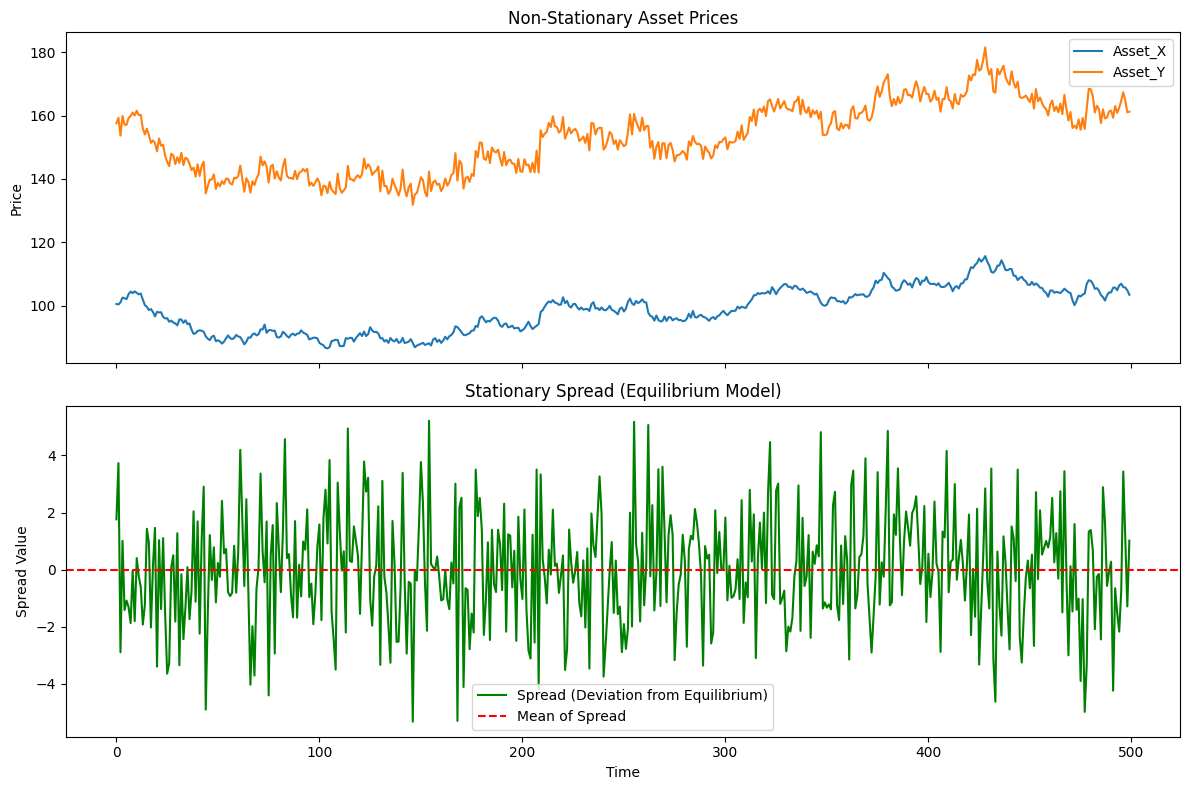


PART 2: REAL MARKET DATA EXAMPLE


/tmp/ipython-input-1-3180680981.py:109: FutureWarning: YF.download() has changed argument auto_adjust default to True
  spy_data = yf.download('SPY', start='2020-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-1-3180680981.py:110: FutureWarning: YF.download() has changed argument auto_adjust default to True
  qqq_data = yf.download('QQQ', start='2020-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed


Analyzing 1006 trading days of data
--- Stationarity Check for SPY_ETF ---
ADF Statistic: -1.2412
p-value: 0.6556
Critical Values:
	1%: -3.4369
	5%: -2.8644
	10%: -2.5683
Conclusion: The series 'SPY_ETF' is likely NON-STATIONARY (p-value >= 0.05).
----------------------------------------
--- Stationarity Check for QQQ_ETF ---
ADF Statistic: -1.3778
p-value: 0.5929
Critical Values:
	1%: -3.4369
	5%: -2.8644
	10%: -2.5683
Conclusion: The series 'QQQ_ETF' is likely NON-STATIONARY (p-value >= 0.05).
----------------------------------------

--- Cointegration Check ---
Cointegration test p-value: 0.5448
Conclusion: The series are likely NOT COINTEGRATED (p-value >= 0.05).

No cointegration found between SPY and QQQ in this period.
This is common - not all asset pairs are cointegrated.

ANALYSIS COMPLETE
Key Takeaways:
1. Individual asset prices are typically non-stationary (random walks)
2. Cointegrated assets have a stationary linear combination (spread)
3. The spread mean-reverts, enablin

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
import matplotlib.pyplot as plt
import yfinance as yf

def check_stationarity(series: pd.Series, series_name: str):
    """Performs the Augmented Dickey-Fuller test to check for stationarity."""
    print(f"--- Stationarity Check for {series_name} ---")
    result = adfuller(series)
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.4f}')

    if result[1] < 0.05:
        print(f"Conclusion: The series '{series_name}' is likely STATIONARY (p-value < 0.05).")
    else:
        print(f"Conclusion: The series '{series_name}' is likely NON-STATIONARY (p-value >= 0.05).")
    print("-" * 40)
    return result[1] < 0.05

def find_cointegration(series1: pd.Series, series2: pd.Series):
    """Tests for cointegration between two series and finds the hedge ratio."""
    print("\n--- Cointegration Check ---")
    coint_test_result = coint(series1, series2)
    print(f"Cointegration test p-value: {coint_test_result[1]:.4f}")

    if coint_test_result[1] < 0.05:
        print("Conclusion: The series are likely COINTEGRATED (p-value < 0.05).")
        series2_with_const = sm.add_constant(series2)
        model = sm.OLS(series1, series2_with_const).fit()
        hedge_ratio = model.params.iloc[1]
        intercept = model.params.iloc[0]
        print(f"Equilibrium relationship: {series1.name} = {hedge_ratio:.4f} * {series2.name} + {intercept:.4f}")
        return hedge_ratio, intercept
    else:
        print("Conclusion: The series are likely NOT COINTEGRATED (p-value >= 0.05).")
        return None, None

def plot_results(series1: pd.Series, series2: pd.Series, spread: pd.Series):
    """Visualizes the original series and the resulting stationary spread."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Plot original series
    ax1.plot(series1, label=series1.name)
    ax1.plot(series2, label=series2.name)
    ax1.set_title('Non-Stationary Asset Prices')
    ax1.set_ylabel('Price')
    ax1.legend()

    # Plot the stationary spread
    ax2.plot(spread, label='Spread (Deviation from Equilibrium)', color='green')
    ax2.axhline(spread.mean(), color='red', linestyle='--', label='Mean of Spread')
    ax2.set_title('Stationary Spread (Equilibrium Model)')
    ax2.set_ylabel('Spread Value')
    ax2.set_xlabel('Time')
    ax2.legend()

    plt.tight_layout()
    plt.show()

def synthetic_example():
    """Demonstrates cointegration with synthetic data."""
    print("="*60)
    print("PART 1: SYNTHETIC DATA EXAMPLE (Perfect Cointegration)")
    print("="*60)

    np.random.seed(42)
    n_samples = 500

    # Asset X follows a random walk
    x_shocks = np.random.randn(n_samples)
    asset_x = pd.Series(np.cumsum(x_shocks) + 100, name='Asset_X')

    # Asset Y is cointegrated with Asset X: Y = 1.5 * X + 5 + noise
    equilibrium_error = np.random.randn(n_samples) * 2
    asset_y = pd.Series(1.5 * asset_x + 5 + equilibrium_error, name='Asset_Y')

    # Test for stationarity
    check_stationarity(asset_x, 'Asset_X')
    check_stationarity(asset_y, 'Asset_Y')

    # Test for cointegration
    hedge_ratio, intercept = find_cointegration(asset_y, asset_x)

    if hedge_ratio is not None:
        spread = asset_y - hedge_ratio * asset_x - intercept
        spread.name = 'Spread'

        print("\n--- Stationarity Check for the Spread ---")
        is_spread_stationary = check_stationarity(spread, 'Spread')

        if is_spread_stationary:
            print("\nSUCCESS: Equilibrium model created! The spread is stationary and mean-reverting.")
            print(f"Trading Strategy: When spread deviates from mean, it will revert.")
            plot_results(asset_x, asset_y, spread)

def real_data_example():
    """Demonstrates analysis with real market data."""
    print("\n" + "="*60)
    print("PART 2: REAL MARKET DATA EXAMPLE")
    print("="*60)

    try:
        # Download real data - using SPY and QQQ (both track US market)
        spy_data = yf.download('SPY', start='2020-01-01', end='2024-01-01')
        qqq_data = yf.download('QQQ', start='2020-01-01', end='2024-01-01')

        asset_x = spy_data[('Close', 'SPY')].dropna()
        asset_y = qqq_data[('Close', 'QQQ')].dropna()
        asset_x.name = 'SPY_ETF'
        asset_y.name = 'QQQ_ETF'

        # Align data
        common_dates = asset_x.index.intersection(asset_y.index)
        asset_x = asset_x[common_dates]
        asset_y = asset_y[common_dates]

        print(f"Analyzing {len(asset_x)} trading days of data")

        # Test for stationarity
        check_stationarity(asset_x, 'SPY_ETF')
        check_stationarity(asset_y, 'QQQ_ETF')

        # Test for cointegration
        hedge_ratio, intercept = find_cointegration(asset_y, asset_x)

        if hedge_ratio is not None:
            spread = asset_y - hedge_ratio * asset_x - intercept
            spread.name = 'Spread'

            print("\n--- Stationarity Check for the Spread ---")
            is_spread_stationary = check_stationarity(spread, 'Spread')

            if is_spread_stationary:
                print("\nSUCCESS: Found cointegration in real market data!")
                print(f"Hedge Ratio: {hedge_ratio:.4f}")
                print(f"Trading Strategy:")
                print(f"  - When spread > mean: Short QQQ, Long {hedge_ratio:.2f} shares of SPY")
                print(f"  - When spread < mean: Long QQQ, Short {hedge_ratio:.2f} shares of SPY")
                plot_results(asset_x, asset_y, spread)
            else:
                print("\nThe spread is not stationary - no strong cointegration found.")
        else:
            print("\nNo cointegration found between SPY and QQQ in this period.")
            print("This is common - not all asset pairs are cointegrated.")

    except Exception as e:
        print(f"Error downloading real data: {e}")
        print("Proceeding with synthetic example only.")

def main():
    """Main function to run both examples."""
    print("WQU QUANTITATIVE FINANCE: Non-Stationarity and Equilibrium Model")
    print("This demonstrates key concepts in pairs trading and statistical arbitrage")

    # Run synthetic example (guaranteed to work)
    synthetic_example()

    # Run real data example
    real_data_example()

    print("\n" + "="*60)
    print("ANALYSIS COMPLETE")
    print("="*60)
    print("Key Takeaways:")
    print("1. Individual asset prices are typically non-stationary (random walks)")
    print("2. Cointegrated assets have a stationary linear combination (spread)")
    print("3. The spread mean-reverts, enabling statistical arbitrage strategies")
    print("4. Real market cointegration is less perfect than synthetic examples")

if __name__ == "__main__":
    main()